In [1]:
import matplotlib.pyplot as plt
import numpy as np
from shared import set_custom_style

# Set custom plot style
set_custom_style()

['#5842ff', '#ff4000', '#00b368']

In [2]:
tick = 3.0
gcd = 2.5
x_gcd = np.arange(0, 33, gcd)
t_repertoire = np.arange(tick / 2, 33, tick)

In [3]:
def sample_ap_gcds(ap_duration, gcd=2.50, ea_after_ap=True):
    n_gcds = []

    # Outer loop to collect statistics
    for a in range(100000):
        # t = 0 is when AP is applied
        # Where the first GCD is depends on whether AP is used in
        # the first or second weave slot.
        # This is a rough estimate.
        if ea_after_ap:
            x_gcd = [2.0]
        else:
            x_gcd = [0.75]

        x_repertoire = np.arange(3, ap_duration + 3, tick)

        current_gcd = 2.50
        # Account for already having one
        n_rep = 1 if ea_after_ap else 0
        idx = 0

        # Hacky way of getting an EA to increase stacks
        # Assuming already at 4 stacks by second EA usage
        use_ea = not ea_after_ap
        ea_time_relative = 14.5

        while x_gcd[idx] <= ap_duration:
            x_gcd.append(x_gcd[idx] + current_gcd)

            # Remove all previous ticks
            last_tick = x_repertoire[x_repertoire < x_gcd[idx]]

            # There can be two GCDs between ticks
            # list will be empty, so don't check for new ticks
            if last_tick.size > 0:
                last_tick = last_tick.argmax()
                x_repertoire = x_repertoire[last_tick + 1 :]

                # Do we get repertoire proc?
                repertoire = np.random.binomial(1, 0.8)
                # If so cap it at 4 stacks
                n_rep = min(4, n_rep + repertoire)
                # Update next GCD
                rep_multiplier = 1 - (0.04 * n_rep)
                current_gcd = 2.5 * rep_multiplier

            # Use EA once to increase stacks
            if (x_gcd[idx] > ea_time_relative) & use_ea:
                n_rep = min(4, n_rep + 1)
                use_ea = False
            idx += 1

        n_gcds.append(len(x_gcd))

    print(x_repertoire[0] // 3)
    print(x_repertoire)
    return np.array(n_gcds), x_gcd

In [4]:
n_gcds_27, sample_x_gcd = sample_ap_gcds(27, ea_after_ap=False)
n_gcds_36, _ = sample_ap_gcds(36, ea_after_ap=True)

9.0
[27.]
12.0
[36.]


[0.75, 3.25, 5.75, 8.15, 10.55, 12.950000000000001, 15.350000000000001, 17.650000000000002, 19.85, 22.05, 24.150000000000002, 26.250000000000004, 28.350000000000005]


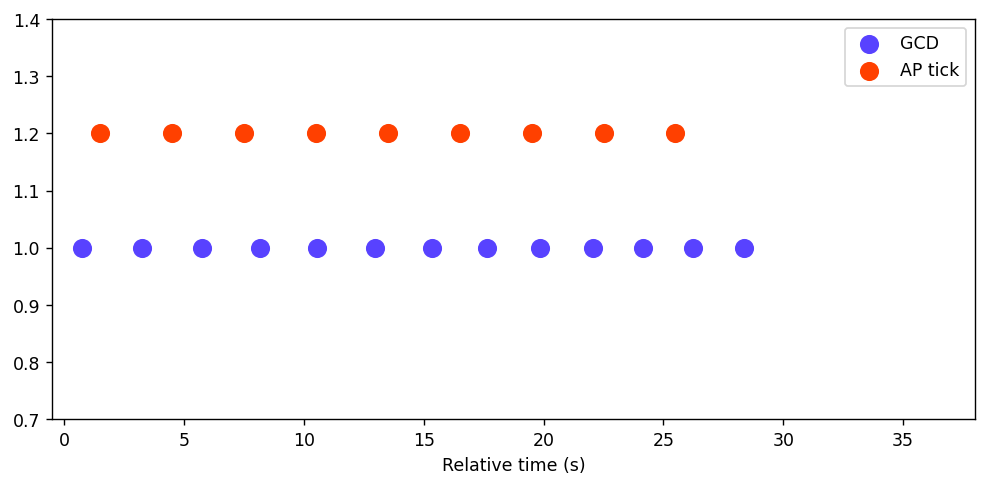

In [5]:
print(sample_x_gcd)
fig, ax = plt.subplots(1, 1, figsize=(8, 4), dpi=125)
ax.scatter(sample_x_gcd, np.ones(len(sample_x_gcd)), s=100, label="GCD")
ax.scatter(
    t_repertoire[:-2], np.ones(t_repertoire[:-2].shape) + 0.2, s=100, label="AP tick"
)
ax.set_ylim([0.7, 1.4])
ax.set_xlabel("Relative time (s)")
ax.set_xlim([-0.5, 38])
ax.legend()
plt.tight_layout()
plt.show()

Haste buff is small enough that there's no variability in number of GCDs during AP.

For shorter AP durations, around 30s, there was about a 2% chance of getting 1 fewer GCD, but it's so small it's not worth considering. Just going to ignore this, especially when considering RA procs during RA.

0.99489


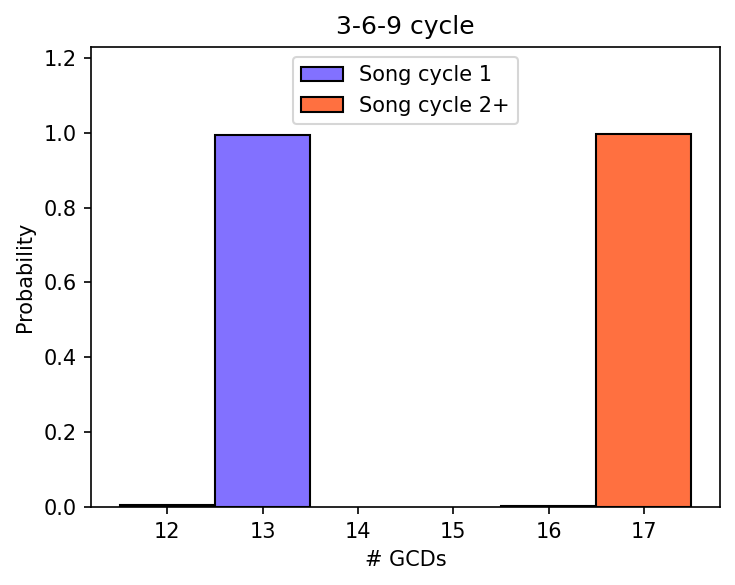

In [6]:
import seaborn as sns

fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=150)
print(n_gcds_27[n_gcds_27 == 13].size / n_gcds_27.size)
sns.histplot(
    n_gcds_27,
    discrete=True,
    stat="probability",
    ax=ax,
    label="Song cycle 1",
    multiple="dodge",
)
sns.histplot(
    n_gcds_36,
    discrete=True,
    stat="probability",
    ax=ax,
    label="Song cycle 2+",
    multiple="dodge",
)
ax.set_title("3-6-9 cycle")

ax.legend(loc="upper center")
ax.set_xlabel("# GCDs")
ax.set_ylim([0, 1.23])
plt.tight_layout()
plt.savefig("../tex/img/ap-gcd-var.png")
plt.show()